# Неделя 17. Backpropagation в NumPy: каждую производную можно проверить

**Tech Orda · Gizatov A. S. · beginner ML/AI · Python 3**

**Практика:** 54 минуты; первая практическая часть недели. На неделе также 72 минуты разбора теории: всего
2 занятия × 90 минут = 4 академических часа. Домашнее задание выполняется отдельно.

**Результат:** реализовать softmax cross-entropy и двухслойную сеть, проверить градиенты конечными разностями, выбрать checkpoint по validation и оценить закрытый test.

Ячейки идут от постановки задачи и описательной аналитики к алгоритму,
проверке и интерпретации. Сначала предскажите результат ячейки, затем запускайте.
Данные уже находятся в `../datasets`; интернет, GPU и API-ключи не нужны.
Запуск: **Restart Kernel → Run All**. Зависимости устанавливаются заранее
по инструкции в корне репозитория; из notebook ничего не устанавливается.


In [1]:
# Ограничиваем число потоков: небольшие учебные задачи запускаются на CPU.
import os
for variable in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(variable, "1")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split

SEED = 42
rng = np.random.default_rng(SEED)
# Поддерживается запуск из корня репозитория, practice/ и homework/.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "course_plan.json").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Откройте notebook внутри клонированного репозитория")
WEEK = ROOT / 'week_17_backprop_frameworks'
DATA = WEEK / "datasets"
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True,
                      "grid.alpha": 0.2, "font.size": 10})


## Локальные digits 8×8 и единая разбивка

Одна строка — 64 пикселя и цифра 0…9. Известный диапазон пикселя 0…16
позволяет делить на 16 без оценки статистик по данным. Сначала 20% test,
затем 25% оставшихся строк на validation: примерно **60/20/20**.
`sample_id` и target исключены из X. Все три лабораторные недели используют
одинаковые индексы; test не выбирает число эпох.


In [2]:
df = pd.read_csv(DATA / "digits_8x8.csv").set_index("sample_id")
assert df.index.is_unique and df.notna().all().all()
pixels = df.drop(columns="target")
assert pixels.shape[1] == 64 and pixels.min().min() >= 0 and pixels.max().max() <= 16
all_ids = df.index.to_numpy()
trainval_ids, test_ids = train_test_split(all_ids, test_size=0.2,
    stratify=df.target, random_state=SEED)
train_ids, val_ids = train_test_split(trainval_ids, test_size=0.25,
    stratify=df.loc[trainval_ids, "target"], random_state=SEED + 1)
assert set(train_ids).isdisjoint(val_ids) and set(trainval_ids).isdisjoint(test_ids)
def arrays(ids):
    return (pixels.loc[ids].to_numpy(dtype="float32") / 16.0,
            df.loc[ids, "target"].to_numpy(dtype="int64"))
X_train, y_train = arrays(train_ids)
X_val, y_val = arrays(val_ids)
X_test, y_test = arrays(test_ids)
print({"train": X_train.shape, "validation": X_val.shape, "sealed_test": X_test.shape})


{'train': (1077, 64), 'validation': (360, 64), 'sealed_test': (360, 64)}


## EDA только train: баланс, распределение и изображения

Изображения уже уменьшены до 8×8, поэтому детали потеряны. Нулевые края
встречаются часто. В исходном экспорте нет ID автора почерка: random split
не проверяет перенос на полностью новых авторов. Сравнение framework на одном
seed — учебная иллюстрация, не рейтинг библиотек.


0    107
1    109
2    106
3    109
4    109
5    109
6    109
7    107
8    104
9    108
Name: train_count, dtype: int64

,mean,std,min,max
0,0.000,0.000,0.0,0.000
1,0.019,0.059,0.0,0.500
2,0.323,0.295,0.0,1.000
3,0.738,0.267,0.0,1.000
4,0.745,0.265,0.0,1.000
5,0.374,0.358,0.0,1.000
6,0.089,0.214,0.0,1.000
7,0.009,0.069,0.0,0.938
8,0.000,0.005,0.0,0.125
9,0.128,0.203,0.0,0.938


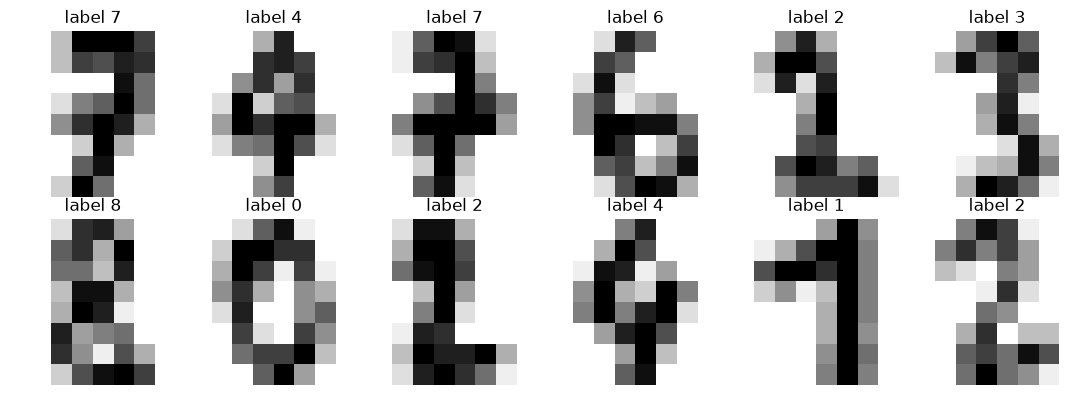

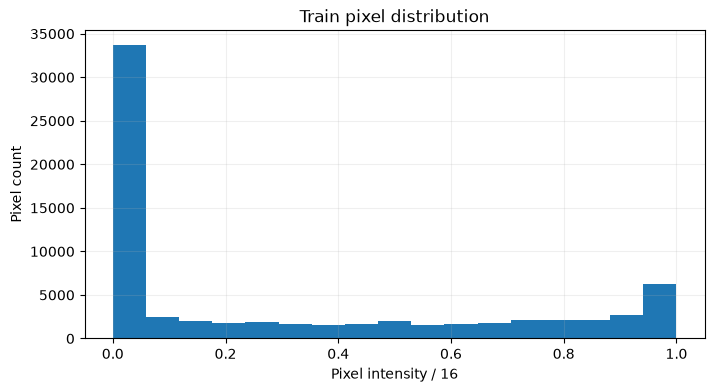

In [3]:
display(pd.Series(y_train).value_counts().sort_index().rename("train_count"))
display(pd.DataFrame(X_train).describe().T[["mean", "std", "min", "max"]].head(12).round(3))
fig, axes = plt.subplots(2, 6, figsize=(11, 4))
for ax, image, label in zip(axes.ravel(), X_train[:12], y_train[:12]):
    ax.imshow(image.reshape(8, 8), cmap="gray_r", vmin=0, vmax=1)
    ax.set_title(f"label {label}"); ax.axis("off")
plt.tight_layout(); plt.show()
plt.hist(X_train.ravel(), bins=17)
plt.xlabel("Pixel intensity / 16"); plt.ylabel("Pixel count"); plt.title("Train pixel distribution")
plt.show()


## 1. Forward pass и функция потерь

$$H=\tanh(XW_1+b_1),\quad Z=HW_2+b_2,$$
$$p_{ik}=\frac{e^{Z_{ik}}}{\sum_j e^{Z_{ij}}},\quad
L=-\frac1n\sum_i\log p_{i,y_i}.$$

Вычитаем максимум из logits каждой строки, чтобы избежать переполнения exp.
Вычитание одной константы не меняет softmax. Скрытый слой имеет 32 нейрона.


In [4]:
def softmax(logits):
    shifted = logits-logits.max(axis=1, keepdims=True)
    exponent = np.exp(shifted)
    return exponent/exponent.sum(axis=1, keepdims=True)
probe_probability = softmax(np.array([[1000., 1001., 999.]]))
assert np.allclose(probe_probability.sum(axis=1), 1) and np.isfinite(probe_probability).all()
params = {
    "W1": rng.normal(0, np.sqrt(1/64), (64, 32)), "b1": np.zeros((1, 32)),
    "W2": rng.normal(0, np.sqrt(1/32), (32, 10)), "b2": np.zeros((1, 10))}
def forward(parameters, X):
    hidden = np.tanh(X @ parameters["W1"] + parameters["b1"])
    logits = hidden @ parameters["W2"] + parameters["b2"]
    return hidden, logits, softmax(logits)
print("Число обучаемых параметров:", sum(value.size for value in params.values()))


Число обучаемых параметров: 2410


## 2. Chain rule: от loss к каждому весу

Для softmax + cross-entropy $dZ=(P-Y)/n$.
$$dW_2=H^TdZ,\quad db_2=\sum_i dZ_i,$$
$$dH=dZW_2^T,\quad dA_1=dH\odot(1-H^2),$$
$$dW_1=X^TdA_1,\quad db_1=\sum_i dA_{1,i}.$$

`keepdims=True` сохраняет форму bias. Деление на n уже выполнено в dZ:
повторное деление сделало бы градиент слишком маленьким.


In [5]:
def loss_and_gradients(parameters, X, y):
    hidden, logits, probability = forward(parameters, X)
    shifted = logits-logits.max(axis=1, keepdims=True)
    log_probability = shifted-np.log(np.exp(shifted).sum(axis=1, keepdims=True))
    loss = -log_probability[np.arange(len(y)), y].mean()
    d_logits = probability.copy()
    d_logits[np.arange(len(y)), y] -= 1
    d_logits /= len(y)
    d_hidden_pre = (d_logits @ parameters["W2"].T) * (1-hidden**2)
    gradients = {"W2": hidden.T @ d_logits, "b2": d_logits.sum(axis=0, keepdims=True),
                 "W1": X.T @ d_hidden_pre, "b1": d_hidden_pre.sum(axis=0, keepdims=True)}
    return loss, gradients
initial_loss, initial_gradients = loss_and_gradients(params, X_train[:32], y_train[:32])
assert np.isfinite(initial_loss)
for key in params:
    assert initial_gradients[key].shape == params[key].shape
print("Initial batch loss:", initial_loss)


Initial batch loss: 2.5274426027527053


## 3. Gradient check: проверяем производную, а не красивую accuracy

Берём по четыре заранее воспроизводимые координаты каждого массива параметров.
Центральная разность приближает производную. Делаем это на float64 и небольшом
batch, до обучения. Если проверка не проходит, сначала исправляют backprop,
а не увеличивают число эпох.


In [6]:
X_probe, y_probe = X_train[:8].astype("float64"), y_train[:8]
_, analytical = loss_and_gradients(params, X_probe, y_probe)
eps, checks = 1e-5, []
check_rng = np.random.default_rng(SEED)
for key, values in params.items():
    for flat_index in check_rng.choice(values.size, size=min(4, values.size), replace=False):
        index = np.unravel_index(flat_index, values.shape)
        original = values[index]
        values[index] = original+eps; plus, _ = loss_and_gradients(params, X_probe, y_probe)
        values[index] = original-eps; minus, _ = loss_and_gradients(params, X_probe, y_probe)
        values[index] = original
        numeric = (plus-minus)/(2*eps)
        exact = analytical[key][index]
        checks.append({"parameter": key, "index": str(index), "analytic": exact,
                       "numeric": numeric, "absolute_error": abs(exact-numeric)})
gradient_check = pd.DataFrame(checks)
display(gradient_check)
assert gradient_check.absolute_error.max() < 1e-6


,parameter,index,analytic,numeric,absolute_error
0,W1,"(np.int64(28), np.int64(2))",0.040305,0.040305,3.667358e-12
1,W1,"(np.int64(5), np.int64(22))",0.069676,0.069676,2.562357e-11
2,W1,"(np.int64(41), np.int64(27))",-0.003758,-0.003758,1.001761e-11
3,W1,"(np.int64(49), np.int64(15))",0.000000,0.000000,0.000000e+00
4,b1,"(np.int64(0), np.int64(20))",0.025943,0.025943,8.601845e-12
5,b1,"(np.int64(0), np.int64(6))",0.011280,0.011280,5.247242e-12
6,b1,"(np.int64(0), np.int64(2))",0.022290,0.022290,2.794716e-12
7,b1,"(np.int64(0), np.int64(16))",-0.001759,-0.001759,8.610294e-12
8,W2,"(np.int64(22), np.int64(7))",0.035121,0.035121,1.864932e-12
9,W2,"(np.int64(16), np.int64(3))",-0.022984,-0.022984,5.702546e-12


## 4. Обучение и validation checkpoint

Один epoch здесь — один full-batch шаг на всех train-строках. Минимизируем train loss,
а лучшую копию весов сохраняем по validation loss. Test не влияет ни на шаг,
ни на количество эпох. Число 180 и learning rate 0.5 заданы до запуска.


In [7]:
learning_rate, epochs = 0.5, 180
history, best_val_loss, best_params, best_epoch = [], np.inf, None, None
for epoch in range(1, epochs+1):
    train_loss, gradients = loss_and_gradients(params, X_train, y_train)
    for key in params:
        params[key] -= learning_rate * gradients[key]
    val_loss, _ = loss_and_gradients(params, X_val, y_val)
    val_probability = forward(params, X_val)[2]
    history.append({"epoch": epoch, "train_loss_before_update": train_loss,
                    "validation_loss_after_update": val_loss,
                    "validation_accuracy": (val_probability.argmax(axis=1)==y_val).mean()})
    if val_loss < best_val_loss:
        best_val_loss, best_epoch = val_loss, epoch
        best_params = {key: value.copy() for key, value in params.items()}
history = pd.DataFrame(history)
assert np.isfinite(history.select_dtypes("number")).all().all()
assert history.train_loss_before_update.iloc[-1] < history.train_loss_before_update.iloc[0]
print("Validation checkpoint epoch:", best_epoch)


Validation checkpoint epoch: 180


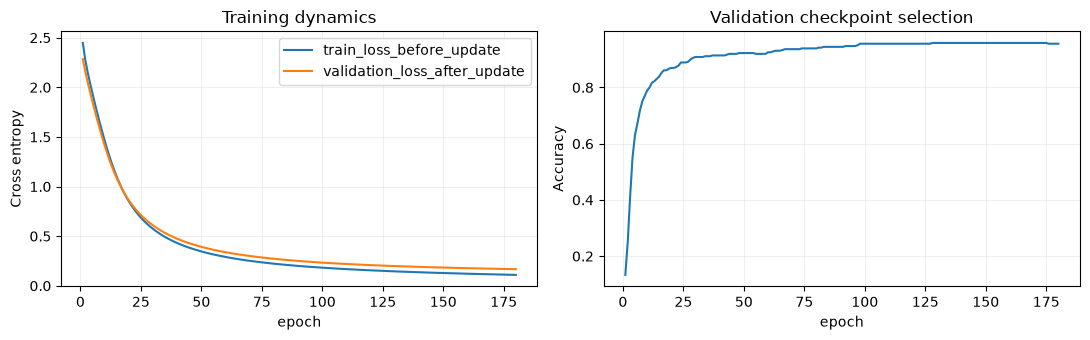

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
history.plot(x="epoch", y=["train_loss_before_update", "validation_loss_after_update"], ax=axes[0])
axes[0].set(ylabel="Cross entropy", title="Training dynamics")
history.plot(x="epoch", y="validation_accuracy", ax=axes[1], legend=False)
axes[1].set(ylabel="Accuracy", title="Validation checkpoint selection")
plt.tight_layout(); plt.show()


## 5. Итоговый test и baseline

Восстанавливаем **лучший validation checkpoint**, затем впервые считаем test.
Для классификации десяти цифр baseline выбирает наиболее частую цифру train.
Не подбираем сеть после просмотра матрицы ошибок.


Baseline test accuracy: 0.1
NumPy MLP test accuracy: 0.95
              precision    recall  f1-score   support

           0       1.00      0.97      0.99        36
           1       0.88      0.81      0.84        36
           2       1.00      1.00      1.00        35
           3       0.97      0.97      0.97        37
           4       0.92      1.00      0.96        36
           5       0.97      1.00      0.99        37
           6       0.95      0.97      0.96        36
           7       0.97      0.97      0.97        36
           8       0.91      0.86      0.88        35
           9       0.92      0.94      0.93        36

    accuracy                           0.95       360
   macro avg       0.95      0.95      0.95       360
weighted avg       0.95      0.95      0.95       360



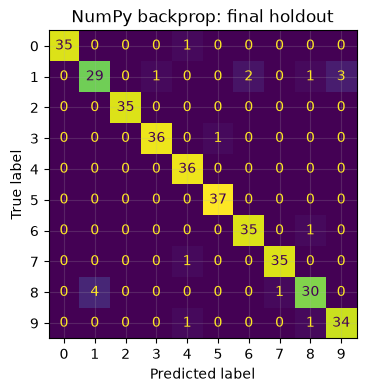

In [9]:
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
test_probability = forward(best_params, X_test)[2]
prediction = test_probability.argmax(axis=1)
baseline_prediction = np.full(len(y_test), np.bincount(y_train).argmax())
print("Baseline test accuracy:", accuracy_score(y_test, baseline_prediction))
print("NumPy MLP test accuracy:", accuracy_score(y_test, prediction))
print(classification_report(y_test, prediction, zero_division=0))
assert np.allclose(test_probability.sum(axis=1), 1) and prediction.shape == y_test.shape
ConfusionMatrixDisplay.from_predictions(y_test, prediction, colorbar=False)
plt.title("NumPy backprop: final holdout"); plt.show()


## 6. Что именно проверено

Softmax устойчив к большим logits; формы градиентов совпадают с параметрами;
выбранные производные совпали с конечными разностями; train loss уменьшился;
checkpoint выбран без test. Gradient check охватывает 16 координат, а не
доказывает правильность любой возможной сети или любого batch.

**Перед следующим lab:** объясните, что в PyTorch/TensorFlow заменит функцию
`loss_and_gradients`, где хранится градиент и почему optimizer не должен видеть test.

Источники: [Stanford CS231n backprop](https://cs231n.github.io/optimization-2/),
[Stanford CS231n neural networks](https://cs231n.github.io/neural-networks-1/),
[MIT Introduction to Deep Learning](https://introtodeeplearning.com/).
